# Within-song effects in starlings: Fig. 5 A-E and Supplementary Fig. S6

Reads one file, `within_song_data.pkl`, written by the data notebook, and nothing else.

| Panel | What it shows | Output file |
|---|---|---|
| Fig. 5A | Two syllable types across song position in one bird, heliox vs regular air | `fig5A_syllable_usage` |
| Fig. 5B | Divergence (JSD) between the two conditions across song position, one row per bird | `fig5B_jsd_heatmap` |
| Fig. 5C | JSD in the early, mid and late thirds of the song | `fig5C_jsd_thirds` |
| Fig. 5D | Tempo traces of a low-roughness and a high-roughness song | `fig5D_tempo_examples` |
| Fig. 5E | Heliox effect on jump rate, pause fraction and roughness | `fig5E_tempo_effects` |
| Supp. S6 A-B | Every syllable type across sequence position in one bird, by condition | `suppS6AB_syllable_usage` |
| Supp. S6C | Total variation (TV) distance in the three thirds of the song | `suppS6C_tv_thirds` |
| Supp. S6D | TV distance across song position with the mixed-model slope | `suppS6D_tv_slope` |

Each figure is saved as PNG and PDF. **Run order:** top to bottom.

In [1]:
# Cell 1: settings and data
import os, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import statsmodels.formula.api as smf
from scipy import stats
from scipy.interpolate import interp1d

# Paths relative to the repository, so a fresh clone runs without edits (from the repo folder or
# from notebooks/). To use other copies, e.g. on the cluster: export HELIOX_DATA_DIR=/path/to/data/derived
REPO = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA_DIR = os.environ.get('HELIOX_DATA_DIR', os.path.join(REPO, 'data'))
OUT_DIR = os.environ.get('HELIOX_FIG_DIR', os.path.join(REPO, 'figures'))
DATA_PATH = os.path.join(DATA_DIR, 'within_song_data.pkl')
os.makedirs(OUT_DIR, exist_ok=True)

with open(DATA_PATH, 'rb') as f:
    D = pickle.load(f)
print(f"data built {D['meta']['created']}")
for name, df in D.items():
    if name != 'meta':
        print(f'  {name:15s} {len(df):>6d} rows')

syl = D['syllables']
syl = syl[syl['label'] >= 0]            # unclustered syllables (label -1) take no part in any panel
tempo = D['tempo_songs'].copy()
BIRDS = sorted(syl['bird'].unique())
BIRD_COLORS = {bird: plt.cm.tab10(i / 10) for i, bird in enumerate(BIRDS)}
THIRDS = ['Early\n(0-33%)', 'Mid\n(33-67%)', 'Late\n(67-100%)']
STATS = []                              # every number on the panels, collected for Cell 10

plt.rcParams.update({'font.size': 16, 'axes.titlesize': 18, 'axes.labelsize': 17,
                     'xtick.labelsize': 15, 'ytick.labelsize': 15, 'legend.fontsize': 14})


def stars(p):
    return '***' if p < 1e-3 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'


def save(name):
    for ext in ('png', 'pdf'):
        plt.savefig(os.path.join(OUT_DIR, f'{name}.{ext}'), dpi=300, bbox_inches='tight')

data built 2026-10-11T12:11:05
  syllables        62090 rows
  tempo_songs       1568 rows
  tempo_examples     131 rows


## Syllable usage across song position (Fig. 5 A-C, Supp. Fig. S6)

A syllable's position is its index within the bout. For each bird, the range of positions
is cut into equal bins; in each bin the regular air and heliox distributions over syllable
types are compared with the Jensen-Shannon divergence (JSD) and the total variation (TV)
distance. A bin counts only if both conditions have enough syllables in it.

In [2]:
# Cell 2: divergence between conditions, bird by position bin
def divergence_by_position(n_bins, min_n):
    """One row per bird x retained bin, with `position` rescaled to 0 (the bird's first
    retained bin) to 1 (its last) and the third of the song the bin falls in."""
    rows = []
    for bird in BIRDS:
        b = syl[syl['bird'] == bird]
        edges = np.linspace(b['position'].min(), b['position'].max(), n_bins + 1)
        mids = (edges[:-1] + edges[1:]) / 2
        in_bin = pd.cut(b['position'], bins=edges, include_lowest=True, labels=False)
        types = sorted(b['label'].unique())
        for k in range(n_bins):
            reg = b.loc[(b['condition'] == 'regair') & (in_bin == k), 'label'].value_counts()
            hel = b.loc[(b['condition'] == 'heliox') & (in_bin == k), 'label'].value_counts()
            if reg.sum() < min_n or hel.sum() < min_n:
                continue
            p = reg.reindex(types, fill_value=0).values / reg.sum()
            q = hel.reindex(types, fill_value=0).values / hel.sum()
            m = 0.5 * (p + q)
            rows.append(dict(bird=bird, bin=k, mid=mids[k],
                             tv=0.5 * np.sum(np.abs(p - q)),
                             jsd=0.5 * (stats.entropy(p + 1e-12, m + 1e-12) + stats.entropy(q + 1e-12, m + 1e-12))))
    out = pd.DataFrame(rows)
    out['position'] = out.groupby('bird')['mid'].transform(lambda x: (x - x.min()) / (x.max() - x.min() + 1e-12))
    out['third'] = pd.cut(out['position'], bins=[0, 1 / 3, 2 / 3, 1.0], labels=THIRDS, include_lowest=True)
    return out


div = divergence_by_position(n_bins=20, min_n=15)     # Fig. 5C, S6 C-D and both slope models
by_third = div.groupby(['bird', 'third'], observed=True)[['tv', 'jsd']].mean().reset_index()
print('bins retained per bird (of 20):', div.groupby('bird').size().to_dict())


def usage(bird, condition, by, bins):
    """Share of each syllable type (columns) among the syllables in each position bin (rows)."""
    b = syl[(syl['bird'] == bird) & (syl['condition'] == condition)]
    counts = pd.crosstab(pd.cut(b[by], bins=bins, include_lowest=True, labels=False), b['label'])
    return counts.div(counts.sum(axis=1), axis=0)

bins retained per bird (of 20): {'s_b1349h_23': 7, 's_b1354_25': 14, 's_b1364_25': 17, 's_b1481h_24': 11, 's_b1484h_24': 13, 's_b1556h_24': 12}


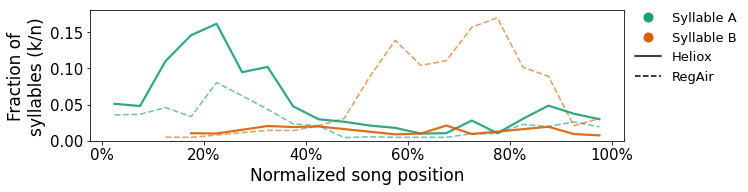

In [3]:
# Cell 3: Fig. 5A, two syllable types in one bird
EXAMPLE_BIRD = 's_b1484h_24'
EXAMPLE_TYPES = {37: ('Syllable A', '#1b9e77'), 3: ('Syllable B', '#d95f02')}     # cluster label: name, color
bins = np.linspace(0, 1, 21)                                                      # 20 bins of normalized position
mids = (bins[:-1] + bins[1:]) / 2

fig, ax = plt.subplots(figsize=(10.5, 2.8))
for cond, style in [('heliox', dict(ls='-', lw=2.2, alpha=0.9, zorder=3)),
                    ('regair', dict(ls='--', lw=1.6, alpha=0.6, zorder=2))]:
    share = usage(EXAMPLE_BIRD, cond, 'position_norm', bins)
    for label, (name, color) in EXAMPLE_TYPES.items():
        y = share.get(label, pd.Series(dtype=float))
        y = y[y > 0]                                         # the bins in which this type occurs
        ax.plot(mids[y.index.astype(int)], y.values, color=color, **style)
handles = [plt.Line2D([], [], color=c, marker='o', ls='', ms=9, label=n) for n, c in EXAMPLE_TYPES.values()]
handles += [plt.Line2D([], [], color='k', ls='-', label='Heliox'), plt.Line2D([], [], color='k', ls='--', label='RegAir')]
ax.legend(handles=handles, frameon=False, fontsize=13, loc='upper left', bbox_to_anchor=(1.0, 1.08))
ax.set_ylim(0, 0.18)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_xlabel('Normalized song position')
ax.set_ylabel('Fraction of\nsyllables (k/n)')
plt.tight_layout()
save('fig5A_syllable_usage')
plt.show()

bins retained per bird (of 10): {'s_b1349h_23': 4, 's_b1354_25': 9, 's_b1364_25': 10, 's_b1481h_24': 8, 's_b1484h_24': 9, 's_b1556h_24': 9}


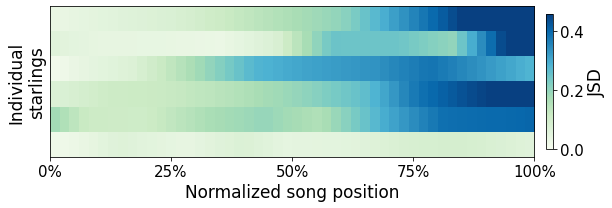

In [4]:
# Cell 4: Fig. 5B, JSD across song position, one row per bird
# A coarser grid (10 bins, 5 syllables minimum) gives every bird a full row. Birds are
# ordered by slope, steepest at the top; values are interpolated along the row for display.
heat = divergence_by_position(n_bins=10, min_n=5)
print('bins retained per bird (of 10):', heat.groupby('bird').size().to_dict())
slope = pd.Series({bird: stats.linregress(g['position'], g['jsd']).slope for bird, g in heat.groupby('bird')})
order = slope.sort_values(ascending=False).index
grid = heat.pivot_table(index='bird', columns='position', values='jsd').reindex(order)

# Layout as published: the distinct positions found across birds are spread evenly along x.
# When every bird keeps all 10 bins, that is exactly normalized position.
x_have, x_draw = np.linspace(0, 1, grid.shape[1]), np.linspace(0, 1, 50)
image = []
for bird in order:
    y = grid.loc[bird].values
    ok = np.isfinite(y)
    image.append(interp1d(x_have[ok], y[ok], kind='linear', bounds_error=False, fill_value='extrapolate')(x_draw))
image = np.clip(np.vstack(image), 0, None)

fig, ax = plt.subplots(figsize=(9, 3))
im = ax.imshow(image, aspect='auto', cmap='GnBu', interpolation='nearest', vmin=0,
               vmax=np.nanpercentile(image, 95), extent=[0, 1, len(order) - 0.5, -0.5])
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_xticklabels(['0%', '25%', '50%', '75%', '100%'])
ax.set_yticks([])
ax.set_xlabel('Normalized song position')
ax.set_ylabel('Individual\nstarlings')
fig.colorbar(im, ax=ax, shrink=0.9, pad=0.02).set_label('JSD')
plt.tight_layout()
save('fig5B_jsd_heatmap')
plt.show()

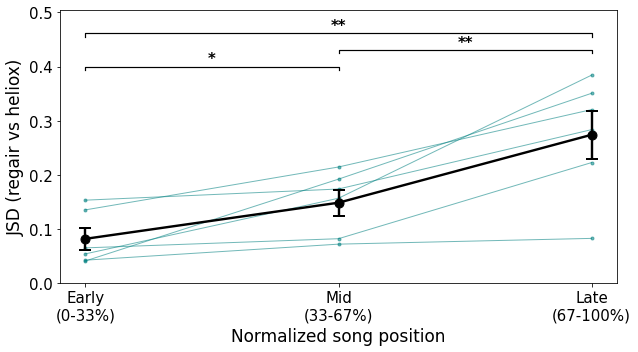

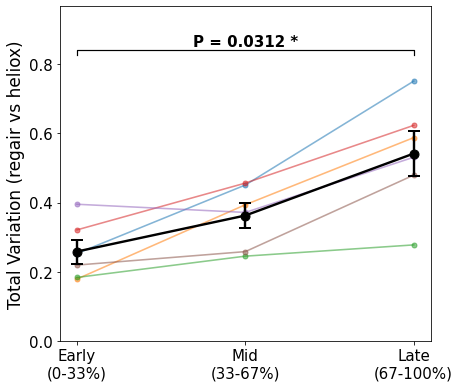

In [5]:
# Cell 5: Fig. 5C and Supp. Fig. S6C, divergence in the three thirds of the song
PAIRS = [(0, 1), (1, 2), (0, 2)]                  # early to mid, mid to late, early to late
PAIR_NAMES = ['early → mid', 'mid → late', 'early → late']


def third_values(metric, i):
    return by_third[by_third['third'] == THIRDS[i]].set_index('bird')[metric]


def compare_thirds(metric, panel):
    """Later third against earlier third, paired by bird. Returns one-tailed t-test P values
    (later is larger) and two-sided Wilcoxon signed-rank P values, one per pair."""
    p_t, p_w = [], []
    for (i, j), name in zip(PAIRS, PAIR_NAMES):
        a, b = third_values(metric, i), third_values(metric, j)
        birds = a.index.intersection(b.index)
        diff = b[birds].values - a[birds].values
        t, p = stats.ttest_1samp(diff, popmean=0, alternative='greater')
        w = stats.wilcoxon(a[birds], b[birds]).pvalue
        STATS.append(dict(panel=panel, comparison=name, quantity=f'{metric.upper()} difference between thirds',
                          estimate=diff.mean(), SE=diff.std(ddof=1) / np.sqrt(len(diff)), t=t, df=len(diff) - 1,
                          P=p, P_wilcoxon=w, n=len(diff), note='P: one-tailed paired t-test'))
        p_t.append(p); p_w.append(w)
    return p_t, p_w


def thirds_panel(ax, metric, colors, lw, ms):
    """Thin lines: each bird's mean in each third. Black: mean ± SEM across birds."""
    for bird, g in by_third.groupby('bird'):
        ax.plot(range(3), g.set_index('third')[metric].reindex(THIRDS).values, color=colors[bird],
                alpha=0.55, lw=lw, marker='o', ms=ms)
    mean_sem = by_third.groupby('third', observed=True)[metric].agg(['mean', 'sem']).reindex(THIRDS)
    ax.errorbar(range(3), mean_sem['mean'], yerr=mean_sem['sem'], color='k', lw=2.4, marker='o', ms=9,
                capsize=6, capthick=2, zorder=5)
    ax.set_xticks(range(3))
    ax.set_xticklabels(THIRDS)


def bracket(ax, x0, x1, y, tick, text):
    ax.plot([x0, x0, x1, x1], [y - tick, y, y, y - tick], color='k', lw=1.2)
    ax.text((x0 + x1) / 2, y + tick * 0.05, text, ha='center', va='bottom', fontsize=15, fontweight='bold')


# ---- Fig. 5C: JSD, one-tailed paired t-tests for each pair of thirds
p_t, _ = compare_thirds('jsd', '5C')
fig, ax = plt.subplots(figsize=(9, 5))
thirds_panel(ax, 'jsd', {bird: 'teal' for bird in BIRDS}, lw=1, ms=3)
top = by_third['jsd'].max()
for row, ((i, j), p) in enumerate(zip(PAIRS, p_t)):
    bracket(ax, i, j, top * (1.04 + 0.08 * row), top * 0.015, stars(p))
ax.set_ylim(0, top * (1.04 + 0.08 * 3.4))
ax.set_xlabel('Normalized song position')
ax.set_ylabel('JSD (regair vs heliox)')
plt.tight_layout()
save('fig5C_jsd_thirds')
plt.show()

# ---- Supp. Fig. S6C: TV, early against late (two-sided Wilcoxon signed-rank, as on the published panel)
_, p_w = compare_thirds('tv', 'S6C')
fig, ax = plt.subplots(figsize=(6.5, 5.5))
thirds_panel(ax, 'tv', BIRD_COLORS, lw=1.6, ms=5)
top = by_third['tv'].max()
bracket(ax, 0, 2, top * 1.12, top * 0.02, f'P = {p_w[2]:.4f} {stars(p_w[2])}')
ax.set_ylim(0, top * 1.17 * 1.1)
ax.set_ylabel('Total Variation (regair vs heliox)')
plt.tight_layout()
save('suppS6C_tv_thirds')
plt.show()

## Tempo (Fig. 5 D-E)

Tempo is the interval between successive syllable onsets. Each song gets three numbers:
jump rate (share of steps between successive tempo values above 15 ms), pause fraction
(share of intervals longer than twice the song's median) and roughness (median absolute
step between successive tempo values).

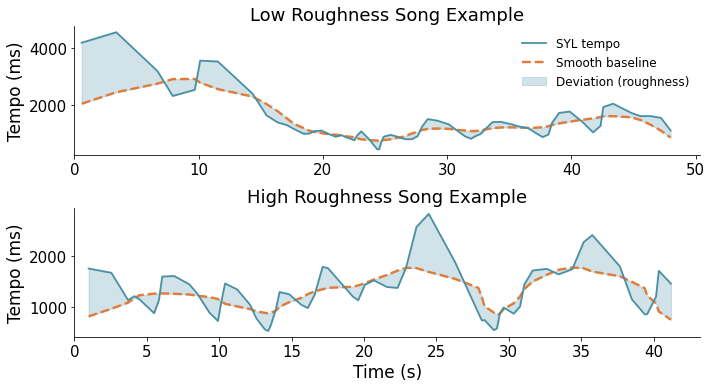

In [6]:
# Cell 6: Fig. 5D, a low-roughness and a high-roughness song
def display_trace(onsets_s):
    """Interval from each onset to the next but one (ms), with a 5-point Hanning smooth."""
    t = np.sort(np.asarray(onsets_s, float))
    dt = t[2:] - t[:-2]
    w = np.hanning(min(5, len(dt)))
    return t[:-2], np.convolve(dt, w / (np.sum(w) + 1e-12), mode='same') * 1000.0


def smooth_baseline(y, n=15):
    """The trace under a wider (15-point) Hanning window."""
    n = min(n, len(y))
    w = np.hanning(max(3, n - 1 if n % 2 == 0 else n))
    return np.convolve(y, w / (np.sum(w) + 1e-12), mode='same')


examples = D['tempo_examples']
if examples['example'].nunique() < 2:
    print('Fig. 5D not drawn: the data notebook has not been told which two songs to use (TEMPO_EXAMPLES, Cell W1).')
else:
    fig, axes = plt.subplots(2, 1, figsize=(10, 5.5))
    for ax, which in zip(axes, ['low', 'high']):
        song = examples[examples['example'] == which]
        t, y = display_trace(song['onset_s'])
        base = smooth_baseline(y)
        ax.plot(t, y, color='#4A90A4', lw=1.8, zorder=3, label='SYL tempo')
        ax.plot(t, base, color='#E07B39', lw=2.4, ls='--', zorder=2, label='Smooth baseline')
        ax.fill_between(t, y, base, color='#4A90A4', alpha=0.25, label='Deviation (roughness)')
        ax.set_title(f'{which.capitalize()} Roughness Song Example')
        ax.set_ylabel('Tempo (ms)')
        ax.set_xlim(left=0)
        for side in ('top', 'right'):
            ax.spines[side].set_visible(False)
        STATS.append(dict(panel='5D', comparison=f'{which} roughness example', quantity='roughness of this song (ms)',
                          estimate=song['tempo_roughness_ms'].iloc[0], n=len(song),
                          note=f"{song['bird'].iloc[0]}, {song['condition'].iloc[0]}, {song['song_file'].iloc[0]}"))
    axes[0].legend(frameon=False, fontsize=12, loc='upper right')
    axes[1].set_xlabel('Time (s)')
    plt.tight_layout()
    save('fig5D_tempo_examples')
    plt.show()

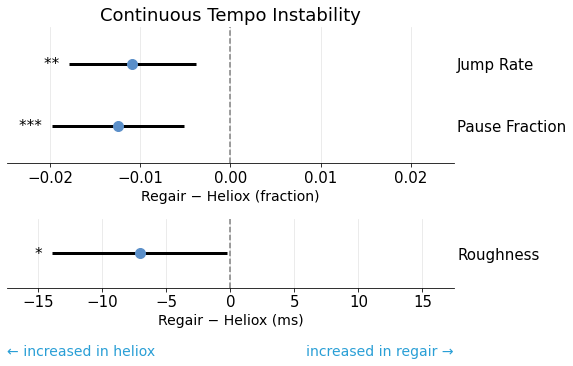

In [7]:
# Cell 7: Fig. 5E, heliox effect on each tempo metric
# One model per metric: metric ~ condition + (1 | bird), fit by maximum likelihood.
# Effects are Regair − Heliox, so a negative value means the metric is larger under heliox.
METRICS = [('tempo_jump_rate', 'Jump Rate'), ('tempo_pause_frac', 'Pause Fraction'), ('tempo_roughness_ms', 'Roughness')]
tempo['heliox'] = (tempo['condition'] == 'heliox').astype(int)

effects = {}
for column, name in METRICS:
    d = tempo[np.isfinite(tempo[column])]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')          # boundary warnings are recorded below instead of printed
        fit = smf.mixedlm(f'{column} ~ heliox', d, groups=d['bird']).fit(reml=False, method='lbfgs', disp=False)
    lo, hi = fit.conf_int().loc['heliox']
    bird_var = float(fit.cov_re.iloc[0, 0])
    effects[name] = dict(estimate=-fit.params['heliox'], CI_low=-hi, CI_high=-lo, P=fit.pvalues['heliox'])
    STATS.append(dict(panel='5E', comparison=name, quantity='Regair − Heliox', SE=fit.bse['heliox'],
                      z=-fit.tvalues['heliox'], n=len(d), **effects[name],
                      note=f"{int((d['heliox'] == 0).sum())} regair + {int((d['heliox'] == 1).sum())} heliox songs; "
                           + ('bird variance estimated as 0' if bird_var < 1e-12 else f'bird variance {bird_var:.3g}')))

fig, axes = plt.subplots(2, 1, figsize=(8, 4.8), gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.55})
for ax, names, unit in [(axes[0], ['Jump Rate', 'Pause Fraction'], 'fraction'), (axes[1], ['Roughness'], 'ms')]:
    for y, name in zip(range(len(names))[::-1], names):
        e = effects[name]
        ax.plot([e['CI_low'], e['CI_high']], [y, y], color='k', lw=3, solid_capstyle='butt')
        ax.plot(e['estimate'], y, 'o', color='#5b8fc9', ms=10, zorder=3)
        ax.text(e['CI_low'], y, stars(e['P']) + '  ', ha='right', va='center', fontsize=15)
    limit = 1.25 * max(abs(v) for n in names for v in (effects[n]['CI_low'], effects[n]['CI_high']))
    ax.set_xlim(-limit, limit)
    ax.set_ylim(-0.6, len(names) - 0.4)
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names[::-1])
    ax.yaxis.tick_right()
    ax.tick_params(axis='y', length=0)
    ax.axvline(0, color='gray', ls='--', lw=1.5)
    ax.grid(axis='x', alpha=0.3)
    ax.set_xlabel(f'Regair − Heliox ({unit})', fontsize=14)
    for side in ('top', 'left', 'right'):
        ax.spines[side].set_visible(False)
axes[0].set_title('Continuous Tempo Instability')
axes[1].text(0, -1.0, '← increased in heliox', transform=axes[1].transAxes, ha='left', color='#2a9fd6', fontsize=14)
axes[1].text(1, -1.0, 'increased in regair →', transform=axes[1].transAxes, ha='right', color='#2a9fd6', fontsize=14)
save('fig5E_tempo_effects')
plt.show()

## Supplementary Fig. S6 A-B and D

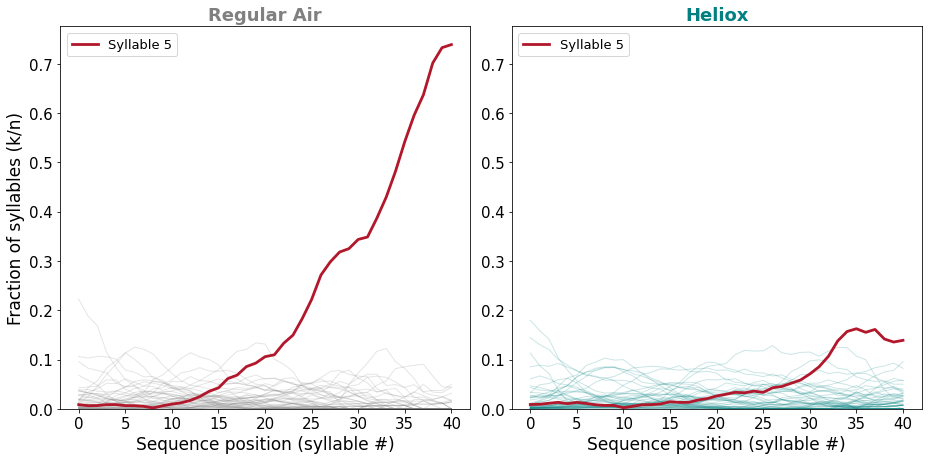

In [8]:
# Cell 8: Supp. Fig. S6 A-B, every syllable type across sequence position in one bird
# Share of each type at each sequence position (0 = first syllable of the bout), smoothed over
# neighbouring positions. The type with the highest peak in regular air is drawn in red.
S6_BIRD = 's_b1349h_23'
S6_LAST_POSITION = 40
S6_SMOOTH = 5                       # positions in the centered rolling mean

shares = {}
for cond in ('regair', 'heliox'):
    share = usage(S6_BIRD, cond, 'position', np.arange(-0.5, S6_LAST_POSITION + 1))
    share = share.reindex(index=range(S6_LAST_POSITION + 1), columns=sorted(syl.loc[syl['bird'] == S6_BIRD, 'label'].unique()),
                          fill_value=0.0)
    shares[cond] = share.rolling(S6_SMOOTH, center=True, min_periods=1).mean()
top_type = shares['regair'].max().idxmax()

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), sharey=True)
for ax, cond, title, color in [(axes[0], 'regair', 'Regular Air', 'gray'), (axes[1], 'heliox', 'Heliox', 'teal')]:
    ax.plot(shares[cond].drop(columns=top_type), color=color, alpha=0.2, lw=1)
    ax.plot(shares[cond][top_type], color='#b2182b', lw=2.8, label=f'Syllable {top_type}')
    ax.set_title(title, color=color, fontweight='bold')
    ax.set_xlabel('Sequence position (syllable #)')
    ax.legend(loc='upper left', fontsize=13)
    ax.yaxis.set_tick_params(labelleft=True)
axes[0].set_ylabel('Fraction of syllables (k/n)')
axes[0].set_ylim(bottom=0)
plt.tight_layout()
save('suppS6AB_syllable_usage')
plt.show()

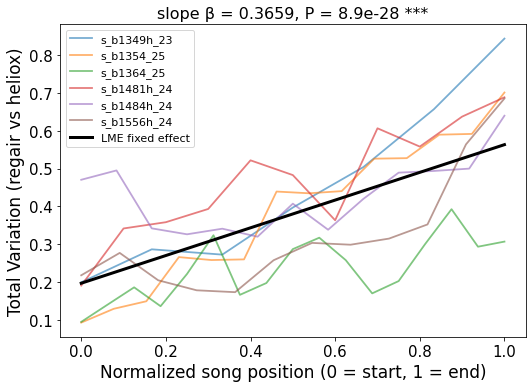

In [9]:
# Cell 9: Supp. Fig. S6D, TV across song position, and the slope models for TV and JSD
# divergence ~ position + (1 | bird), fit by REML. A positive slope means the two conditions
# grow apart toward the end of the song.
slope_fit = {}
for metric, panel in [('tv', 'S6D'), ('jsd', '5B')]:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        fit = smf.mixedlm(f'{metric} ~ position', div, groups=div['bird']).fit(reml=True)
    slope_fit[metric] = fit
    lo, hi = fit.conf_int().loc['position']
    STATS.append(dict(panel=panel, comparison=f'{metric.upper()} slope', quantity=f'{metric.upper()} per unit of song position',
                      estimate=fit.params['position'], SE=fit.bse['position'], CI_low=lo, CI_high=hi,
                      z=fit.tvalues['position'], P=fit.pvalues['position'], n=len(div),
                      note=f"{div['bird'].nunique()} birds; intercept {fit.params['Intercept']:.4f}"))

fit = slope_fit['tv']
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for bird, g in div.groupby('bird'):
    g = g.sort_values('position')
    ax.plot(g['position'], g['tv'], color=BIRD_COLORS[bird], alpha=0.6, lw=1.8, label=bird)
x = np.linspace(0, 1, 100)
ax.plot(x, fit.params['Intercept'] + fit.params['position'] * x, color='k', lw=3, label='LME fixed effect')
ax.set_xlabel('Normalized song position (0 = start, 1 = end)')
ax.set_ylabel('Total Variation (regair vs heliox)')
ax.set_title(f"slope β = {fit.params['position']:.4f}, P = {fit.pvalues['position']:.1e} {stars(fit.pvalues['position'])}",
             fontsize=16)
ax.legend(fontsize=11, loc='upper left')
plt.tight_layout()
save('suppS6D_tv_slope')
plt.show()

In [10]:
# Cell 10: the numbers
table = pd.DataFrame(STATS).reindex(columns=['panel', 'comparison', 'quantity', 'estimate', 'SE', 'CI_low', 'CI_high',
                                             't', 'z', 'df', 'P', 'P_wilcoxon', 'n', 'note'])
table.to_csv(os.path.join(OUT_DIR, 'within_song_statistics.csv'), index=False)
with pd.option_context('display.width', 250, 'display.max_colwidth', 60):
    print(table.drop(columns='quantity').to_string(index=False, float_format=lambda v: f'{v:.4g}'))



panel             comparison  estimate       SE  CI_low   CI_high     t      z  df         P  P_wilcoxon    n                                                                                    note
   5C            early → mid   0.06664  0.02201     NaN       NaN 3.028    NaN   5   0.01458     0.03125    6                                                             P: one-tailed paired t-test
   5C             mid → late    0.1254  0.02914     NaN       NaN 4.303    NaN   5  0.003848     0.03125    6                                                             P: one-tailed paired t-test
   5C           early → late     0.192  0.04505     NaN       NaN 4.262    NaN   5  0.004001     0.03125    6                                                             P: one-tailed paired t-test
  S6C            early → mid    0.1038  0.03837     NaN       NaN 2.706    NaN   5   0.02124      0.0625    6                                                             P: one-tailed paired t-test
  S6C     